# Lecture 6. Introduction to numerical methods

**Convex optimization, Fall 2026**

> A numerical method is a rule for the next point, together with a theorem that says how fast a named residual goes to zero on a named class of functions.

- Lecture 1 used a solver as a black box and said what a convergence bound promises. 
- Today the method is gradient descent. 
- The classes are $L$-smooth, convex, and strongly convex, and the bounds are proved rather than quoted. 
- Each proof produces a step size. 
- The second half of the lecture is what to do when that step size is known, estimated, or unavailable: on a quadratic, where the bounds are sharp, on logistic regression, and on a function with several minima.

## Plan

1. An iteration, an oracle, and three residuals
2. The classes behind the proofs: $L$-smooth, convex, strongly convex
3. Gradient descent on each class, and the step the proof uses
4. What each bound guarantees, and where it stops being informative
5. Choosing the step: constant, exact line search, Armijo, diminishing, Polyak
6. Three tests: a convex quadratic, logistic loss, a nonconvex landscape

- Notation is lecture 1's. $\|\cdot\|$ is the Euclidean norm, $f'$ is the gradient, $f^\star$ is the optimal value.
- Strong convexity is the definition from lecture 2.
- The notebook uses NumPy and Matplotlib only.


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 10,
    }
)

# 1. An iteration and an oracle

- Unconstrained problem: minimize $f:\mathbb{R}^n\to\mathbb{R}$.

- A method sees $f$ through an **oracle**. Gradient descent uses the first-order oracle $\mathbf{x}\mapsto\bigl(f(\mathbf{x}), f'(\mathbf{x})\bigr)$,

$$
\mathbf{x}^{k+1} = \mathbf{x}^k - \eta_k\, f'(\mathbf{x}^k), \qquad \eta_k>0.
$$

- The number $\eta_k$ is the **step size**. Everything below is a choice of $\eta_k$ and a theorem about the sequence it produces.

- One reading of the update: $\mathbf{x}^{k+1}$ is the minimizer of the quadratic model

$$
m_k(\mathbf{y})
= f(\mathbf{x}^k) + \langle f'(\mathbf{x}^k), \mathbf{y}-\mathbf{x}^k\rangle + \frac{1}{2\eta_k}\|\mathbf{y}-\mathbf{x}^k\|^2.
$$

- The curvature $1/\eta_k$ is a guess at the curvature of $f$. A long step is an optimistic model. A short step is a pessimistic one. The theorems say which guess is legal for which class.

## Three residuals

- $\mathbf{x}^\star$ denotes a minimizer, when one exists.

| Residual | Definition | The setting in which it is the certificate |
|---|---|---|
| function gap | $f(\mathbf{x})-f^\star$ | convex $f$: a small gap is near-optimality |
| distance | $\Vert \mathbf{x}-\mathbf{x}^\star\Vert$ | strongly convex $f$: the minimizer is unique |
| stationarity | $\Vert f'(\mathbf{x})\Vert$ | nonconvex $f$: a first-order method can certify a small gradient |

- A small gradient becomes a small gap only after an inequality that connects them.
- Convexity supplies one direction of that inequality. Strong convexity supplies the other.
- Without those inequalities, $f'(\mathbf{x})=\mathbf{0}$ holds at a local minimum, at a saddle, and at a local maximum.
- Iteration complexity counts oracle calls.
- The bounds below are about the iteration count. The dimension $n$ does not appear in them.


## Rates, as budgets

- A bound becomes a budget when it is inverted: the smallest $k$ that forces the residual below $\varepsilon$.
- **Sublinear**, of order $1/k$. One extra digit, $\varepsilon\mapsto\varepsilon/10$, multiplies the budget by $10$.
- **Linear**, of the form $C(1-\rho)^k$ with $\rho\in(0,1)$. One extra digit costs $\log(10)/\rho$ further iterations, however many digits are already in hand.
- Since $(1-\rho)^k\le e^{-\rho k}$, a gap below $\varepsilon$ is guaranteed once $k\ge \rho^{-1}\log(C/\varepsilon)$.
- The constant in front of $k$ is the content of the result. The rates $1-1/\kappa$ and $1-1/\sqrt{\kappa}$ differ by a factor $\sqrt{\kappa}$ in the budget, and for $\kappa=10^6$ that factor is one thousand.
- Lecture 1 compared gradient descent and Nesterov by this factor, on smooth convex problems: the optimal first-order rate is of order $1/k^2$, and gradient descent proves $1/k$.
- A bound holds for every function in the class and every start the hypothesis allows.


# 2. Three classes

- Each proof uses a quadratic model and nothing else.
- The class says which model is legal.

## $L$-smooth: a quadratic upper bound

- $f$ is **$L$-smooth** when the gradient is $L$-Lipschitz,

$$
\|f'(\mathbf{x})-f'(\mathbf{y})\|\le L\|\mathbf{x}-\mathbf{y}\|.
$$

- If $f$ is twice differentiable this is $\|f''(\mathbf{x})\|_2\le L$: every eigenvalue of the Hessian lies in $[-L,L]$.

- **Descent lemma.** For all $\mathbf{x},\mathbf{y}$,

$$
f(\mathbf{y})
\le f(\mathbf{x}) + \langle f'(\mathbf{x}), \mathbf{y}-\mathbf{x}\rangle + \frac{L}{2}\|\mathbf{y}-\mathbf{x}\|^2.
$$

- The right-hand side is the model $m_k$ with curvature $L$, that is with step $1/L$.
- The model lies above the graph.
- Minimizing it decreases $f$, and the decrease can be read off the model.


## What one gradient step decreases

- Substitute $\mathbf{y}=\mathbf{x}-\eta f'(\mathbf{x})$:

$$
f\bigl(\mathbf{x}-\eta f'(\mathbf{x})\bigr)
\le f(\mathbf{x}) - \eta\Bigl(1-\frac{L\eta}{2}\Bigr)\|f'(\mathbf{x})\|^2.
$$

- Every step $\eta\in(0, 2/L)$ decreases $f$, strictly unless the gradient vanishes.
- The decrease $\eta(1-L\eta/2)$ is largest at $\eta=1/L$, where

$$
f(\mathbf{x}^+) \le f(\mathbf{x}) - \frac{1}{2L}\|f'(\mathbf{x})\|^2.
$$

- Past $2/L$ the lemma stops promising decrease.
- On a quadratic whose largest eigenvalue equals $L$, that eigen-component is multiplied by $1-\eta L$.
- $|1-\eta L|>1$ as soon as $\eta>2/L$, and the iteration grows exponentially.
- The threshold in the lemma is the threshold in the recurrence.
- $L$-smoothness is an upper model. The graph may bend down as fast as it bends up.
- A point with $f'(\mathbf{x})=\mathbf{0}$ is a critical point. It may be a minimum, a saddle, or a maximum.


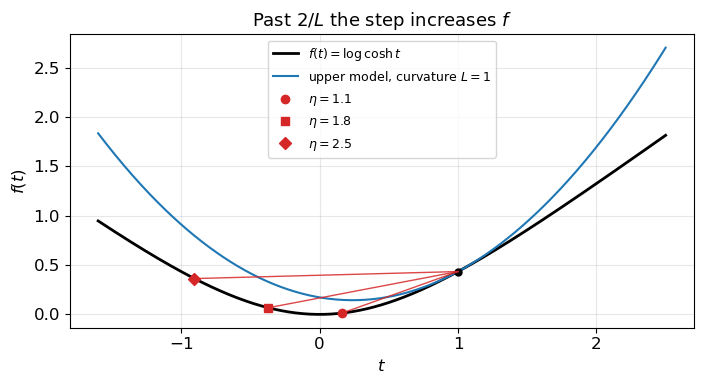

f(x0) = 0.4338
  eta=0.5  f(x+)=0.1806  decrease=+0.2532
  eta=1.0  f(x+)=0.0282  decrease=+0.4056
  eta=1.8  f(x+)=0.0673  decrease=+0.3665
  eta=2.5  f(x+)=0.3627  decrease=+0.0711


In [3]:
# log(cosh) has second derivative sech^2, hence L = 1, and the upper model is global.
def f_cosh(t):
    return np.log(np.cosh(t))

def df_cosh(t):
    return np.tanh(t)

x0 = 1.
g0 = df_cosh(x0)
L_cosh = 1.0
t = np.linspace(-1.6, 2.5, 400)
upper = f_cosh(x0) + g0 * (t - x0) + 0.5 * L_cosh * (t - x0) ** 2

fig, ax = plt.subplots()
ax.plot(t, f_cosh(t), color="k", lw=2, label=r"$f(t)=\log\cosh t$")
ax.plot(t, upper, color="C0", lw=1.5, label=r"upper model, curvature $L=1$")
ax.plot(x0, f_cosh(x0), "o", color="k", ms=5)
for eta, marker in ((1.1, "o"), (1.8, "s"), (2.5, "D")):
    x1 = x0 - eta * g0
    ax.plot([x0, x1], [f_cosh(x0), f_cosh(x1)], color="C3", lw=1.0, alpha=0.85)
    ax.plot(x1, f_cosh(x1), marker, color="C3", ms=6, label=rf"$\eta={eta}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$f(t)$")
ax.set_title(r"Past $2/L$ the step increases $f$")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print("f(x0) = {:.4f}".format(f_cosh(x0)))
for eta in (0.5, 1.0, 1.8, 2.5):
    x1 = x0 - eta * g0
    print(f"  eta={eta:.1f}  f(x+)={f_cosh(x1):.4f}  decrease={f_cosh(x0) - f_cosh(x1):+.4f}")

## Reading the picture

- $f(t)=\log\cosh t$ satisfies $0\le f''(t)\le 1$, so $L=1$ and $2/L=2$.
- $\eta=1=1/L$ lands almost at the minimizer. The upper model is tight near the origin, where $f''\approx 1$, and this start sits close enough for that step to be nearly exact.
- $\eta=1.8$ is still inside $(0,2/L)$ and still decreases $f$, by less.
- $\eta=2.5$ increases $f$. The decrease lemma does not cover a step this long.
- An overestimate of $L$ shortens the step and slows the method down.
- An underestimate can leave the interval $(0,2/L)$.
- Of the two mistakes, the large estimate of $L$ is the safe one.


## Why a small gradient certifies a small gap

- Apply the descent lemma at $\mathbf{y}=\mathbf{x}-(1/L)f'(\mathbf{x})$:

$$
f^\star
\le f\Bigl(\mathbf{x}-\frac{1}{L}f'(\mathbf{x})\Bigr)
\le f(\mathbf{x}) - \frac{1}{2L}\|f'(\mathbf{x})\|^2.
$$

- Rearranging gives $f(\mathbf{x})-f^\star \ge \|f'(\mathbf{x})\|^2/(2L)$.
- Convexity entered only as $f^\star\le f(\text{anything})$. Smoothness did the rest.
- On this class, driving the gradient to zero and driving the gap to zero are the same task, up to the factor $2L$.
- The matching upper bound $f(\mathbf{x})-f^\star\le\langle f'(\mathbf{x}),\mathbf{x}-\mathbf{x}^\star\rangle$ is convexity written at $\mathbf{x}^\star$.
- The convex convergence proof uses the two together:

$$
\langle f'(\mathbf{x}), \mathbf{x}-\mathbf{x}^\star\rangle
\ge f(\mathbf{x})-f^\star + \frac{1}{2L}\|f'(\mathbf{x})\|^2.
$$


## Strongly convex and $L$-smooth

- Strong convexity with modulus $\mu>0$ means $f-(\mu/2)\|\cdot\|^2$ is convex. In first-order form,

$$
f(\mathbf{y})
\ge f(\mathbf{x}) + \langle f'(\mathbf{x}), \mathbf{y}-\mathbf{x}\rangle + \frac{\mu}{2}\|\mathbf{y}-\mathbf{x}\|^2.
$$

- A minimizer exists and is unique, the gradient is strongly monotone, and $f'(\mathbf{x}^\star)=\mathbf{0}$.
- The **condition number** is $\kappa=L/\mu\ge 1$.
- Every linear rate below depends on the class through $\kappa$ and through nothing else.
- $\kappa=1$ is a round paraboloid. $\kappa\gg 1$ is a long thin valley.

**Polyak–Łojasiewicz.** The linear rate on the gap uses

$$
\|f'(\mathbf{x})\|^2 \ge 2\mu\bigl(f(\mathbf{x})-f^\star\bigr).
$$

- The quadratic lower model, minimized over $\mathbf{y}$, takes the value $f(\mathbf{x})-\|f'(\mathbf{x})\|^2/(2\mu)$.
- Since $f$ lies above that model, so does $f^\star$, and rearranging gives the inequality.
- Curvature $\mu$ forbids a large gap together with a small gradient.
- The same pair of models gives quadratic growth, which translates a rate on the gap into a rate on the distance and back:

$$
\frac{\mu}{2}\|\mathbf{x}-\mathbf{x}^\star\|^2
\le f(\mathbf{x})-f^\star
\le \frac{L}{2}\|\mathbf{x}-\mathbf{x}^\star\|^2.
$$


# 3. Gradient descent, three theorems

- The iteration is the same throughout: $\mathbf{x}^{k+1}=\mathbf{x}^k-\eta f'(\mathbf{x}^k)$.
- The class changes, the legal step changes, and the residual the theorem controls changes.

## $L$-smooth: stationarity of order $1/k$

- Assume $f$ is $L$-smooth and bounded below by $f_{\inf}$. Take $\eta=1/L$.
- Sum the one-step decrease $f(\mathbf{x}^k)-f(\mathbf{x}^{k+1})\ge \|f'(\mathbf{x}^k)\|^2/(2L)$:

$$
\frac{1}{K}\sum_{k=0}^{K-1}\|f'(\mathbf{x}^k)\|^2
\le \frac{2L}{K}\bigl(f(\mathbf{x}^0)-f_{\inf}\bigr).
$$

- Some iterate in the first $K$ steps therefore satisfies

$$
\min_{k \leq K}\|f'(\mathbf{x}^k)\|
\le \sqrt{\frac{2L\bigl(f(\mathbf{x}^0)-f_{\inf}\bigr)}{K}}.
$$

- The bound is on the **best** gradient norm along the path.
- Gradient norms themselves need not decrease, so the sum does not control the last iterate.

**Budget.**

- An $\varepsilon$-stationary point, meaning $\|f'\|\le\varepsilon$, is guaranteed within this many iterations:

$$
K \ge \frac{2L\bigl(f(\mathbf{x}^0)-f_{\inf}\bigr)}{\varepsilon^2}.
$$

- The cost scales as $1/\varepsilon^2$.


## Where the stationarity bound stops

- It holds with no convexity, with a dimension-free constant, and with an explicit step.
- The certificate is stationarity.
- A local minimum, a saddle, and a local maximum are all stationary.
- Two $\varepsilon$-stationary points can have very different function values. The last section draws that fact.
- The $1/\varepsilon^2$ scaling is the right order for the class: some $L$-smooth functions force every first-order method to use on the order of $1/\varepsilon^2$ gradient queries.
- A better power of $\varepsilon$ requires a stronger class. Convexity is that class, in the next theorem.
- The hypothesis is a **global** Lipschitz constant of the gradient.
- The function $t\mapsto t^4$ is smooth at every point and has no such $L$ on $\mathbb{R}$.
- On that function a constant step is a guess, and the guess can diverge.
- Backtracking, later, uses only the local curvature along the segment it actually travels.


## $L$-smooth and convex: a gap of order $1/k$

- Assume in addition that $f$ is convex, that a minimizer $\mathbf{x}^\star$ exists, and that $\|\mathbf{x}^0-\mathbf{x}^\star\|\le R$.
- For any fixed step $\eta\in(0, 1/L]$,

$$
\|\mathbf{x}^{k+1}-\mathbf{x}^\star\|^2
\le \|\mathbf{x}^k-\mathbf{x}^\star\|^2 - 2\eta\bigl(f(\mathbf{x}^k)-f^\star\bigr).
$$

- Distance to the minimizer never increases, and each unit of gap is charged against that distance.
- Summing $K$ steps,

$$
\frac{1}{K}\sum_{k=0}^{K-1}\bigl(f(\mathbf{x}^k)-f^\star\bigr)
\le \frac{R^2}{2\eta K}.
$$

- Convexity of $f$ passes from the average of the values to the value at the average point $\bar{\mathbf{x}}^K=\frac1K\sum_{k=0}^{K-1}\mathbf{x}^k$.
- With $\eta=1/L$ the values $f(\mathbf{x}^k)$ themselves decrease, by the descent lemma, so the **last** iterate inherits the average:

$$
f(\mathbf{x}^K)-f^\star \le \frac{L R^2}{2K}.
$$

**Budget.**

- Gap at most $\varepsilon$ once $K\ge LR^2/(2\varepsilon)$.
- This is the $O(L/\varepsilon)$ from lecture 1.


## Where the $-2\eta(f-f^\star)$ comes from

- Convexity and $L$-smoothness give, at a minimizer,

$$
\langle f'(\mathbf{x}), \mathbf{x}-\mathbf{x}^\star\rangle
\ge f(\mathbf{x})-f^\star + \frac{1}{2L}\|f'(\mathbf{x})\|^2.
$$

- Expand the distance, write $\mathbf{g}=f'(\mathbf{x})$ and $\delta=f(\mathbf{x})-f^\star$, and insert the inner product:

\begin{align*}
\|\mathbf{x}-\eta\mathbf{g}-\mathbf{x}^\star\|^2
&= \|\mathbf{x}-\mathbf{x}^\star\|^2 - 2\eta\langle\mathbf{g}, \mathbf{x}-\mathbf{x}^\star\rangle + \eta^2\|\mathbf{g}\|^2 \\
&\le \|\mathbf{x}-\mathbf{x}^\star\|^2 - 2\eta\delta - \eta\Bigl(\frac{1}{L}-\eta\Bigr)\|\mathbf{g}\|^2.
\end{align*}

- For $\eta\le 1/L$ the last term is nonnegative and drops out. That is the whole proof.
- The restriction $\eta\le 1/L$ is the place where the upper model absorbs the $\eta^2\|\mathbf{g}\|^2$ from the expansion.
- The same algebra, once the values are monotone, gives the last-iterate bound.
- If the step is legal and the values are not monotone, the surviving guarantee is the one on the average of the first $K$ values.


## Reading the $1/k$ bound

- The bound certifies **global** optimality: on this class a small gap is a small optimality gap.
- The step does not depend on strong convexity.
- If the function is strongly convex, this step remains legal, and the next theorem says the same iteration converges linearly.
- One extra digit multiplies the budget by ten. Reaching $10^{-8}$ from $10^{-2}$ multiplies it by $10^6$.
- The bound is short of the class. The first-order lower bound on $L$-smooth convex functions is of order $1/k^2$ (lecture 1).
- The bound sees $L$ and $R$. It is silent about the condition number.
- A quadratic with $\kappa=2$ and a quadratic with $\kappa=10^4$ share the guarantee whenever they share $L$ and $R$.
- The guarantee is true for both. The well-conditioned one converges linearly, which a $1/k$ upper bound cannot express, so on that function the bound is loose.
- The ill-conditioned one is close to the function the bound was written for.
- An overestimate $L_{\mathrm{est}}\ge L$ may replace $L$. The step shrinks by $L_{\mathrm{est}}/L$ and the bound inflates by the same factor.
- The algorithm needs the number $L$. A particular instance may be much better than the worst function with that $L$.


## $L$-smooth and $\mu$-strongly convex: linear convergence

- Keep $\eta=1/L$.
- One step decreases the value by at least $\|f'\|^2/(2L)$.
- Polyak–Łojasiewicz says $\|f'\|^2\ge 2\mu(f-f^\star)$, so

$$
f(\mathbf{x}^{k+1})-f^\star
\le \Bigl(1-\frac{\mu}{L}\Bigr)\bigl(f(\mathbf{x}^k)-f^\star\bigr)
= \Bigl(1-\frac{1}{\kappa}\Bigr)\bigl(f(\mathbf{x}^k)-f^\star\bigr).
$$

- Therefore

$$
f(\mathbf{x}^k)-f^\star
\le \Bigl(1-\frac{1}{\kappa}\Bigr)^k \bigl(f(\mathbf{x}^0)-f^\star\bigr).
$$

- Since $(1-1/\kappa)^k\le e^{-k/\kappa}$, the gap is below $\varepsilon$ once

$$
k \ge \kappa\,\log\frac{f(\mathbf{x}^0)-f^\star}{\varepsilon}.
$$

- The budget is logarithmic in the accuracy and linear in the condition number.
- High accuracy is cheap. Bad conditioning is the whole cost.
- The value of $\mu$ is used to **quote** the rate.
- The iteration itself is the convex iteration, with the same step $1/L$.
- Whenever $\mu>0$, that iteration contracts at the linear rate, whether or not $\mu$ was known in advance.


## The step a quadratic can justify

- On $f(\mathbf{x})=\tfrac12 \mathbf{x}^\top \mathbf{H}\mathbf{x}$ the iteration multiplies by $I-\eta\mathbf{H}$.
- An eigenvalue $\lambda\in[\mu, L]$ is sent to $1-\eta\lambda$, and the error is multiplied by

$$
\rho(\eta) = \max_{\lambda\in[\mu, L]} |1-\eta\lambda|.
$$

- Balancing the two ends, $1-\eta\mu = -(1-\eta L)$, gives

$$
\eta_\star = \frac{2}{L+\mu}, \qquad \rho(\eta_\star) = \frac{L-\mu}{L+\mu} = \frac{\kappa-1}{\kappa+1}.
$$

- The same step is legal for every $L$-smooth $\mu$-strongly convex function, with the same factor on the distance:

$$
\|\mathbf{x}^k-\mathbf{x}^\star\|
\le \Bigl(\frac{\kappa-1}{\kappa+1}\Bigr)^k \|\mathbf{x}^0-\mathbf{x}^\star\|.
$$

- Compared with the distance factor $1-1/\kappa$ of the step $1/L$, the factor $(\kappa-1)/(\kappa+1)\approx 1-2/\kappa$ roughly halves the iteration count.
- Use $1/L$ when $\mu$ is unknown.
- Use $\eta_\star$ when both constants are known and trusted.
- If $L=\mu$, then $\eta_\star=1/L$ and the minimizer is reached in one step: the model is the function.


## How sharp the two linear bounds are

- On a quadratic, the step $\eta=1/L$ multiplies the stiffest eigen-component by $1-\eta L=0$ and the flattest by $1-\mu/L=1-1/\kappa$.
- Distance in the worst direction contracts by $1-1/\kappa$ per iteration.
- The gap scales as distance squared, so it contracts by $(1-1/\kappa)^2$.
- Polyak–Łojasiewicz plus the descent lemma proved the weaker factor $1-1/\kappa$ on the **gap**.
- The shape is right and the base is off by a square: the proved slope on a semilog plot is half the slope a quadratic actually has.
- The bound with $\eta_\star$ is sharp already on the distance.
- On $f(\mathbf{x})=\tfrac12(\mu x_1^2 + L x_2^2)$, every start has distance factor exactly $(\kappa-1)/(\kappa+1)$ and gap factor exactly $\bigl((\kappa-1)/(\kappa+1)\bigr)^2$.
- Both bounds see the spread of the spectrum. They are silent about the eigenvectors.
- A diagonal Hessian and a dense one with the same eigenvalues give the same guarantee, and, after a rotation of the start, the same errors.
- The sharp gradient-descent factor is still short of the first-order class.
- The optimal linear rate on $L$-smooth $\mu$-strongly convex functions is of order $1-1/\sqrt{\kappa}$, attained by Nesterov's acceleration (lecture 1).
- Gradient descent's $1-2/\kappa$ is the optimal rate **among fixed-step gradient methods on quadratics**.
- Among all first-order methods the optimal rate is the accelerated one.
- For large $\kappa$ the bound is a reason to change the method: precondition, change the metric, or accelerate.
- Running the same iteration longer leaves $\kappa$ in the budget.


## The three bounds side by side

| Class | Step | Guarantee after $K$ steps | Budget for accuracy $\varepsilon$ |
|---|---|---|---|
| $L$-smooth | $1/L$ | $\min_{k<K}\Vert f'(\mathbf{x}^k)\Vert^2 \le 2L\Delta/K$ | $O(L\Delta/\varepsilon^2)$, stationarity |
| $L$-smooth convex | $1/L$ | $f(\mathbf{x}^K)-f^\star \le LR^2/(2K)$ | $O(LR^2/\varepsilon)$, gap |
| $L$-smooth, $\mu$-strongly convex | $1/L$ | gap $\le (1-1/\kappa)^K\Delta$ | $O\bigl(\kappa\log(\Delta/\varepsilon)\bigr)$ |
| same, both constants known | $2/(L+\mu)$ | distance $\le \bigl((\kappa-1)/(\kappa+1)\bigr)^K R$ | $O\bigl(\kappa\log(R/\varepsilon)\bigr)$, better constant |

- Here $\Delta=f(\mathbf{x}^0)-f^\star$ and $R=\|\mathbf{x}^0-\mathbf{x}^\star\|$.
- Convexity replaces stationarity by a global gap, and replaces $1/\varepsilon^2$ by $1/\varepsilon$.
- Strong convexity replaces $1/\varepsilon$ by a logarithm.
- Each assumption is visible in the budget, so each is worth checking.
- The linear row wins at high accuracy. Take $\kappa=10^6$, $\Delta=1$, $L=\kappa$, $R^2=2/\mu=2$.
- At $\varepsilon=10^{-1}$ the linear budget is about $\kappa\log(10)\approx 2\cdot 10^6$, and the convex budget is $LR^2/(2\varepsilon)=10^7$.
- At $\varepsilon=10^{-8}$ the linear budget grows to about $2\cdot 10^7$, and the convex budget to $10^{14}$.
- The logarithm is the reason to care that $\mu$ is positive.
- A large $\kappa$ is a verdict on this iteration: the valley is thin.
- Shrinking the target $\varepsilon$ leaves the valley thin.


# 4. Choosing the step

- The proofs say "use $1/L$" or "use $2/(L+\mu)$".
- Those numbers are properties of a class.
- A given $f$ may come with them, with an overestimate, or with neither.

## Constant steps

- **$\eta=1/L$.** Legal for the three theorems above. The values $f(\mathbf{x}^k)$ decrease. Any $L_{\mathrm{est}}\ge L$ may replace $L$, and the rate degrades by that factor.
- **$\eta=2/(L+\mu)$.** Best fixed step on the strongly convex class, and sharp on quadratics. It needs both constants. Overestimating $\mu$ lengthens the step and can push it through $2/L$.
- **A hand-tuned constant.** The one-dimensional picture still governs it. There is an interval of steps that decrease $f$ at the current point, a smaller interval that the global proofs cover, and a region beyond $2/L$ where the stiffest direction flips and grows.
- On a quadratic the constants are eigenvalues.
- On a logistic loss, $L$ is an eigenvalue of the data Gram matrix and $\mu$ is the coefficient of an explicit quadratic regularizer. Both are computable there.
- On a general differentiable function they are not, which is why the next three rules avoid forming them.


## Exact line search

$$
\eta_k \in \arg\min_{\eta\ge 0} f\bigl(\mathbf{x}^k - \eta\, f'(\mathbf{x}^k)\bigr).
$$

- Along the ray the step is optimal by construction.
- No $L$ and no $\mu$ are required.
- For the quadratic $f(\mathbf{x})=\tfrac12\mathbf{x}^\top\mathbf{H}\mathbf{x}-\mathbf{b}^\top\mathbf{x}$ the line is a parabola, and

$$
\eta_k = \frac{\|\mathbf{g}^k\|^2}{(\mathbf{g}^k)^\top \mathbf{H}\,\mathbf{g}^k}, \qquad \mathbf{g}^k = f'(\mathbf{x}^k).
$$

- A gradient aligned with a flat eigenvector gets a long step.
- A gradient aligned with a stiff one gets a short step.

**Worst-case rate, on this class.** For $L$-smooth $\mu$-strongly convex quadratics,

$$
f(\mathbf{x}^{k+1})-f^\star
\le \Bigl(\frac{\kappa-1}{\kappa+1}\Bigr)^2 \bigl(f(\mathbf{x}^k)-f^\star\bigr).
$$

- The factor matches $\eta_\star$, and the method was not given $\kappa$.
- The price is a one-dimensional minimization at every iteration: closed form for a quadratic, a real line search otherwise.
- The direction is still the gradient.
- Consecutive gradients are orthogonal. The derivative of the restricted function is $-\langle\mathbf{g}^k, \mathbf{g}^{k+1}\rangle$, and it vanishes at the minimizer of the line.
- On a thin ellipse the iterates zigzag. Exact search fixes the length and leaves the direction as it was.
- The factor is a worst case over starts.
- A start whose gradient lies along a single eigenvector is solved in one step, since the Rayleigh quotient returns $1/\lambda$.
- The bound promises the worst start. A kinder start may be dramatically faster. The plots below show both.


## Armijo backtracking

- Ask for sufficient decrease instead of an exact minimum.
- Fix $\alpha\in(0, 1/2]$, $\beta\in(0,1)$, and a trial length $\bar\eta>0$.
- From $\mathbf{x}$ with $\mathbf{g}=f'(\mathbf{x})$, accept the largest $\eta\in\{\bar\eta, \beta\bar\eta, \beta^2\bar\eta, \ldots\}$ such that

$$
f(\mathbf{x}-\eta\mathbf{g}) \le f(\mathbf{x}) - \alpha\,\eta\,\|\mathbf{g}\|^2.
$$

- If $f$ is $L$-smooth and $\alpha\le 1/2$, every trial $\eta\le 1/L$ passes: the descent lemma gives decrease of at least $(\eta/2)\|\mathbf{g}\|^2$.

- The accepted step inherits the $O(1/k)$ and the linear rates, up to the factor $\beta$ in front of $1/L$.
- The order of the complexity is unchanged.

- What this buys:
  - $L$ is never formed. The test uses function values.
  - The same code runs on a function that is smooth only on a sublevel set, where no global $L$ exists. The accepted step is legal for the curvature along the segment that was tested.
  - Decrease of $f$ is enforced at every accepted step, on convex and on nonconvex functions.

- What it costs:
  - Each rejected trial is a function evaluation. 
  - $\alpha$ and $\beta$ are still parameters. $\alpha=1/2$ is the largest value the descent lemma justifies at step $1/L$. A smaller $\alpha$ accepts longer steps. $\beta$ close to $1$ searches more finely and spends more evaluations.
  - The direction is still the gradient.

- In the experiments below:
  - $\alpha=1/2$ and $\beta=1/2$.
  - The next trial starts at the previous accepted step divided by $\beta$, so the step can grow when the local curvature drops.
  - The test decides whether the longer step is legal. It uses the observed decrease, so a global $L$ is not required.


## Diminishing steps

$$
\eta_k = \frac{\eta_0}{\sqrt{k+1}}
\qquad\text{or}\qquad
\eta_k = \frac{\eta_0}{k+1}.
$$

- These rules use no line search.
- On the classes of this lecture, both are a retreat from a constant step.
- For $L$-smooth convex $f$, a constant step already gives $1/k$. The schedule $\eta_k\propto 1/\sqrt{k}$ falls back to the slower scale associated with nonsmooth problems.
- For strongly convex $f$, a constant step gives a linear rate.
- The schedule $\eta_k=1/(\mu(k+k_0))$, with $k_0$ large enough that the first step is at most $1/L$, gives only $1/k$: the tail of the schedule throws away the contraction.
- The classical summable step $\eta_k\propto 1/k$ is the right tool when the gradient is noisy or the function is nonsmooth, outside today's theorems.
- On a deterministic smooth problem it is a baseline that should lose. The plots check that it does.
- Below, both schedules start at a safe height: $\eta_k=(1/L)/\sqrt{k+1}$, and $\eta_k=1/(\mu(k+\kappa))$ so that $\eta_0=1/L$.
- The second schedule knows $\mu$ and still gives up the linear rate. That is why it is included.


## The Polyak step, when $f^\star$ is known

$$
\eta_k = \frac{f(\mathbf{x}^k)-f^\star}{\|f'(\mathbf{x}^k)\|^2}.
$$

- The length is the gap, measured in units of the squared gradient.
- For convex $L$-smooth $f$, the sandwich $\|f'\|^2/(2L)\le f-f^\star$ forces $\eta_k\ge 1/(2L)$.
- The step can also be **larger than $2/L$**.
- A constant step that large diverges.
- This one need not. A long step occurs only when the gradient is small relative to the gap, and the same inner product that proved the convex rate absorbs the $\eta^2\|\mathbf{g}\|^2$ term.
- With $\delta=f(\mathbf{x})-f^\star$ and $\eta=\delta/\|\mathbf{g}\|^2$,

\begin{align*}
\|\mathbf{x}-\eta\mathbf{g}-\mathbf{x}^\star\|^2
&\le \|\mathbf{x}-\mathbf{x}^\star\|^2 - 2\eta\delta - \frac{\eta}{L}\|\mathbf{g}\|^2 + \eta^2\|\mathbf{g}\|^2 \\
&= \|\mathbf{x}-\mathbf{x}^\star\|^2 - \frac{\delta}{L} - \frac{\delta^2}{\|\mathbf{g}\|^2}.
\end{align*}

- Distance to the minimizer decreases at every iteration, by at least $\delta/L$.
- Summing gives an $O(LR^2/K)$ bound on the **average** gap, the same order as the constant step $1/L$.
- The values $f(\mathbf{x}^k)$ themselves need not decrease. The guarantee is on the distance and on the average.
- Under strong convexity, $\delta\ge (\mu/2)\|\mathbf{x}-\mathbf{x}^\star\|^2$ upgrades the recurrence to the factor $1-\mu/(2L)$ on the squared distance.
- That factor is weaker than the factor for the step $1/L$. The plots are often better than the factor, and the proof does not claim the plots.
- The hypothesis is the optimal value.
- A value strictly below $f^\star$ lengthens every step. A value above $f^\star$ shortens them.

## The rules, from the bounds

| Rule | Information it uses | Guarantee it inherits | Characteristic failure |
|---|---|---|---|
| $1/L$ | a true Lipschitz constant | the three theorems, as stated | $L$ unknown, or far larger than the local curvature |
| $2/(L+\mu)$ | both constants, accurately | distance factor $(\kappa-1)/(\kappa+1)$ | $\hat\mu>\mu$ can push the step past $2/L$ |
| exact line search | values of $f$ along the ray | gap factor $\bigl((\kappa-1)/(\kappa+1)\bigr)^2$ on quadratics | cost per iteration; the zigzag remains |
| Armijo, $\alpha=1/2$ | values of $f$ | same order as $1/L$, step at least $\beta/L$ | extra function evaluations |
| $(1/L)/\sqrt{k+1}$ | an upper bound on $L$, then a schedule | sublinear; the linear rate is lost | slow on every problem proved above |
| Polyak | $f^\star$ | distance decreases; average gap $O(LR^2/K)$ | a low guess of $f^\star$; nonconvex basins |

- The quadratic is where the bounds are sharp.
- Logistic regression is a convex loss whose $L$ is a property of the data matrix, and whose strong-convexity modulus may be zero.
- The nonconvex example is where the stationarity bound is the whole guarantee, and where two runs with tiny gradients finish at different values.


# 5. A convex quadratic

- Translate the minimizer to the origin and take a diagonal Hessian.
- Gradient descent is equivariant under orthogonal changes of coordinates, and the bounds depend on the eigenvalues only.

$$
f(\mathbf{x}) = \frac12\sum_{i=1}^n \lambda_i x_i^2,
\qquad
\mu=\lambda_{\min},\quad L=\lambda_{\max},\quad \kappa=L/\mu.
$$

- Then $f'(\mathbf{x})=(\lambda_i x_i)_i$.
- In the pictures $n=2$, $\mu=1$, and $\lambda\in\{1, \kappa\}$, so the level sets are ellipses with axis ratio $\sqrt{\kappa}$.
- The long axis is the flat one.
- The first figure is the geometry of the step.
- The second compares the proved curves with the actual gap, on a balanced start and on a pure flat start.
- The third is the step-selection rules.
- The fourth varies $\kappa$ with the start held fixed, so the change in slope is the condition number and nothing else.


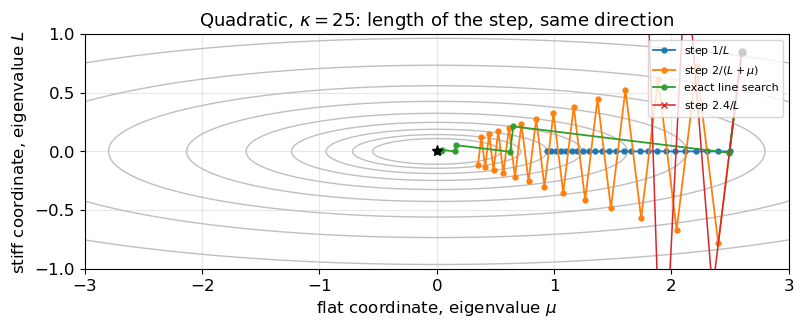

exact line search, first inner products of consecutive gradients:
  [ 0.  0. -0.  0.  0.  0.]
after 4 steps of size 2.4/L, ||x|| = 3.70


In [9]:
def run_quadratic(eigs, x0, n_iter, rule):
    """Gradient descent on f = (1/2) sum eigs[i] * x[i]^2, minimizer at 0.

    eigs must be sorted ascending, so eigs[0] = mu and eigs[-1] = L.
    """
    x = np.array(x0, dtype=float).copy()
    mu = float(eigs[0])
    L = float(eigs[-1])
    kappa = L / mu
    alpha, beta = 0.5, 0.5
    f_hist, g_hist, eta_hist, x_hist = [], [], [], [x.copy()]
    n_f = 0
    eta_prev = 1.0
    for k in range(n_iter):
        g = eigs * x
        gap = 0.5 * float(np.dot(eigs, x * x))
        gn2 = float(np.dot(g, g))
        f_hist.append(gap)
        g_hist.append(np.sqrt(gn2))
        n_f += 1
        if gn2 < 1e-30 or gap < 1e-30:
            eta_hist.append(0.0)
            break
        if rule == "L":
            eta = 1.0 / L
        elif rule == "opt":
            eta = 2.0 / (L + mu)
        elif rule == "exact":
            eta = gn2 / float(np.dot(eigs * g, g))
        elif rule == "armijo":
            eta = 1.0 if k == 0 else eta_prev / beta
            for _ in range(80):
                trial = x - eta * g
                f_try = 0.5 * float(np.dot(eigs, trial * trial))
                n_f += 1
                if f_try <= gap - alpha * eta * gn2:
                    break
                eta *= beta
            eta_prev = eta
        elif rule == "polyak":
            eta = gap / gn2
        elif rule == "sqrt":
            eta = (1.0 / L) / np.sqrt(k + 1.0)
        elif rule == "decay":
            # Knows mu, and still decays. eta_0 = 1/L.
            eta = 1.0 / (mu * (k + kappa))
        else:
            raise ValueError(rule)
        eta_hist.append(float(eta))
        x = x - eta * g
        x_hist.append(x.copy())
        if np.linalg.norm(x) > 1e8:
            break
    return {
        "f": np.asarray(f_hist),
        "gnorm": np.asarray(g_hist),
        "eta": np.asarray(eta_hist),
        "x": np.asarray(x_hist),
        "n_f": n_f,
    }


def positive(values, floor=1e-30):
    out = np.asarray(values, dtype=float).copy()
    out[out < floor] = np.nan
    return out


# --- trajectories on a thin ellipse ---
kappa_picture = 25.0
eigs_picture = np.array([1.0, kappa_picture])
x_start = np.array([2.6,  0.85])
paths = {
    r"step $1/L$": run_quadratic(eigs_picture, x_start, 25, "L"),
    r"step $2/(L+\mu)$": run_quadratic(eigs_picture, x_start, 25, "opt"),
    "exact line search": run_quadratic(eigs_picture, x_start, 25, "exact"),
}
# A step past 2/L, kept only while it remains inside the window.
x = x_start.copy()
div_pts = [x.copy()]
L_picture = kappa_picture
for _ in range(4):
    g = eigs_picture * x
    x = x - (2.4 / L_picture) * g
    div_pts.append(x.copy())
    if np.linalg.norm(x) > 6:
        break
div_pts = np.asarray(div_pts)

flat = np.linspace(-3.4, 3.4, 400)
stiff = np.linspace(-3.6, 3.6, 400)
Fflat, Fstiff = np.meshgrid(flat, stiff)
Z = 0.5 * (eigs_picture[0] * Fflat**2 + eigs_picture[1] * Fstiff**2)

fig, ax = plt.subplots(figsize=(8.2, 7.6))
ax.contour(Fflat, Fstiff, Z, levels=np.geomspace(0.15, 20, 10), colors="0.75", linewidths=1)
for label, hist in paths.items():
    pts = hist["x"]
    ax.plot(pts[:, 0], pts[:, 1], marker="o", ms=3.5, lw=1.3, label=label)
ax.plot(div_pts[:, 0], div_pts[:, 1], marker="x", ms=5, color="C3", lw=1.1, label=r"step $2.4/L$")
ax.plot(x_start[0], x_start[1], "o", color="k", ms=5)
ax.plot(0, 0, "*", color="k", ms=8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-3, 3)
ax.set_ylim(-1, 1)
ax.set_xlabel(r"flat coordinate, eigenvalue $\mu$")
ax.set_ylabel(r"stiff coordinate, eigenvalue $L$")
ax.set_title(rf"Quadratic, $\kappa={kappa_picture:.0f}$: length of the step, same direction")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

# Exact line search: consecutive gradients are orthogonal.
g_hist = eigs_picture * paths["exact line search"]["x"]
dots = [float(np.dot(g_hist[k], g_hist[k + 1])) for k in range(min(6, len(g_hist) - 1))]
print("exact line search, first inner products of consecutive gradients:")
print(" ", np.array2string(np.array(dots), precision=2, suppress_small=True))
print(f"after {len(div_pts) - 1} steps of size 2.4/L, ||x|| = {np.linalg.norm(div_pts[-1]):.2f}")

## Zigzag is the condition number, drawn

- The level sets are ellipses.
- The gradient is orthogonal to the level set, so from a point on the side of the valley it points mostly across the short axis, and a step spends its length there.
- The step $1/L$ annihilates the stiff coordinate in a single iteration, because that coordinate is multiplied by $1-\eta L=0$. The iterate lands on the long axis and then crawls toward the origin at the rate of the flat eigenvalue.
- The step $2/(L+\mu)$ shrinks both coordinates by the same factor $(\kappa-1)/(\kappa+1)$ at every iteration. It gets no free annihilation of the stiff direction, and it never gets stuck with only the flat one.
- Exact line search takes a different length every time. Consecutive gradients are orthogonal, up to roundoff: the inner products printed under the figure are numerical zeros. The path is the zigzag that orthogonality forces, and on this start it reaches the origin first.
- The step $2.4/L$ leaves the window. The factor on the stiff coordinate is $1-2.4=-1.4$, so that coordinate grows by $1.4$ per iteration. The upper limit $2/L$ in the descent lemma is this divergence.
- A shorter constant step, well below $1/L$, would walk the same path as $1/L$ more slowly.
- The comparison that matters is among steps that are actually candidates. It continues on the semilog plots of the gap.


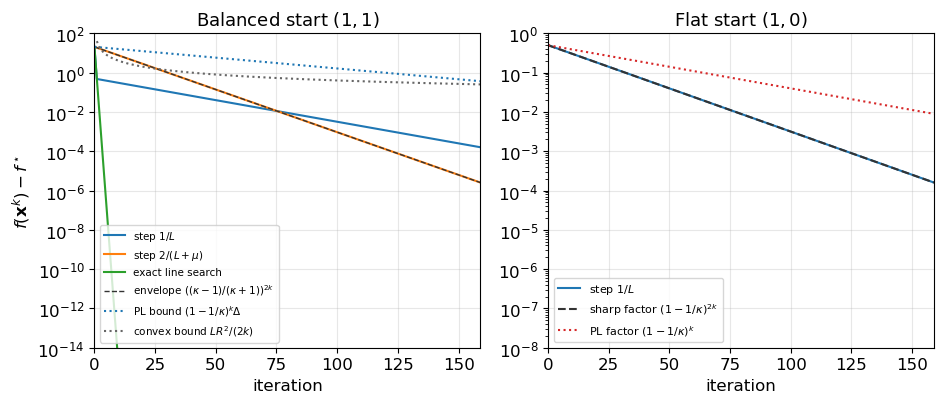

kappa=40, gap0=20.5000, R^2=2
optimal step first beats 1/L at iteration 76
at k=75:  1/L 1.1211e-02   opt 1.1321e-02   PL bound 3.0697e+00   convex bound 5.3333e-01
convex bound holds: max over k of (gap / bound) = 0.0908


In [10]:
kappa = 40.0
mu, L = 1.0, kappa
eigs = np.array([mu, L])
rho = (kappa - 1) / (kappa + 1)
x_balanced = np.array([1.0, 1.0])
x_flat = np.array([1.0, 0.0])
n_show = 160

balanced = {name: run_quadratic(eigs, x_balanced, n_show, name) for name in ("L", "opt", "exact")}
flat = run_quadratic(eigs, x_flat, n_show, "L")

k = np.arange(n_show)
gap0 = balanced["L"]["f"][0]
R2 = float(np.dot(x_balanced, x_balanced))
# Convex bound is infinite at k = 0; draw it from the first completed step.
k_pos = np.arange(1, n_show)
convex_bound = L * R2 / (2.0 * k_pos)
pl_bound = gap0 * (1.0 - 1.0 / kappa) ** k
opt_envelope = gap0 * rho ** (2.0 * k)
# On the flat start the gap really is (1/2) * (1 - 1/kappa)^{2k}.
flat_gap0 = flat["f"][0]
sharp_flat = flat_gap0 * (1.0 - 1.0 / kappa) ** (2.0 * k)
pl_flat = flat_gap0 * (1.0 - 1.0 / kappa) ** k

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))

ax = axes[0]
ax.semilogy(positive(balanced["L"]["f"]), label=r"step $1/L$")
ax.semilogy(positive(balanced["opt"]["f"]), label=r"step $2/(L+\mu)$")
ax.semilogy(positive(balanced["exact"]["f"]), label="exact line search")
ax.semilogy(k, positive(opt_envelope), ls="--", color="0.2", lw=1, label=r"envelope $((\kappa-1)/(\kappa+1))^{2k}$")
ax.semilogy(k, positive(pl_bound), ls=":", color="C0", label=r"PL bound $(1-1/\kappa)^k\Delta$")
ax.semilogy(k_pos, convex_bound, ls=":", color="0.4", label=r"convex bound $LR^2/(2k)$")
ax.set_xlim(0, n_show - 1)
ax.set_ylim(1e-14, 1e2)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(\mathbf{x}^k)-f^\star$")
ax.set_title(r"Balanced start $(1,1)$")
ax.legend(fontsize=7.5, loc="lower left")

ax = axes[1]
ax.semilogy(positive(flat["f"]), color="C0", label=r"step $1/L$")
ax.semilogy(k, positive(sharp_flat), ls="--", color="0.2", label=r"sharp factor $(1-1/\kappa)^{2k}$")
ax.semilogy(k, positive(pl_flat), ls=":", color="C3", label=r"PL factor $(1-1/\kappa)^k$")
ax.set_xlim(0, n_show - 1)
ax.set_ylim(1e-8, 1)
ax.set_xlabel("iteration")
ax.set_title(r"Flat start $(1,0)$")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

# Where the optimal fixed step overtakes 1/L on the balanced start.
f_L = balanced["L"]["f"]
f_opt = balanced["opt"]["f"]
overtake = np.where(f_opt < f_L)[0]
print(f"kappa={kappa:.0f}, gap0={gap0:.4f}, R^2={R2:.0f}")
print(f"optimal step first beats 1/L at iteration {int(overtake[0])}")
print(f"at k=75:  1/L {f_L[75]:.4e}   opt {f_opt[75]:.4e}   PL bound {pl_bound[75]:.4e}   convex bound {convex_bound[74]:.4e}")
ratio = f_L[1:] * (2.0 * k_pos) / (L * R2)
print(f"convex bound holds: max over k of (gap / bound) = {ratio.max():.4f}")

## The $1/k$ bound sits above the curves. One linear bound sits on them.

**Left panel.** Start $(1,1)$, $\kappa=40$, $\mu=1$.

- The initial gap is $\tfrac12(L+\mu)=20.5$, of which the stiff coordinate contributes $20$.
- The step $1/L$ deletes that coordinate at iteration 1.
- The gap falls from $20.5$ to $\tfrac12(1-1/\kappa)^2\approx 0.48$, and from then on it equals $\tfrac12(1-1/\kappa)^{2k}$.
- The step $2/(L+\mu)$ multiplies the gap by $\bigl((\kappa-1)/(\kappa+1)\bigr)^2=(39/41)^2$ at every iteration, including the first.
- Its curve lies on the dashed envelope: on a two-eigenvalue quadratic the bound is an equality for every start.
- The equation $\tfrac12(39/40)^{2k} = 20.5\,(39/41)^{2k}$ has solution $k\approx 75$. The computed curves cross at iteration 76.
- At iteration 75 the two gaps are $1.12\cdot 10^{-2}$ and $1.13\cdot 10^{-2}$.
- The convex bound $LR^2/(2k)=40/k$ equals $0.53$ there.
- The Polyak–Łojasiewicz bound $20.5\,(1-1/\kappa)^k$ equals about $3.1$.
- Both bounds are valid, and both sit far above the curves.
- The convex bound makes no use of $\mu$.
- The Polyak–Łojasiewicz bound charges the whole initial gap at the slower base $1-1/\kappa$.
- Exact line search on this start falls well below the worst-case envelope.
- The envelope is the promise for the worst start. This start is a kind one: after the first step the gradient is nearly an eigenvector, and the Rayleigh quotient finishes the job.

**Right panel.** Start on the flat axis.

- There is no stiff mass to delete, so the step $1/L$ never gets a free first iteration.
- The gap equals $\tfrac12(1-1/\kappa)^{2k}$ from iteration 0, and the dashed line sits under the curve.
- The Polyak–Łojasiewicz line has half the slope: the proved factor is $1-1/\kappa$ on the gap, and the quadratic has the square.
- The proof is one inequality short of the geometry, and the picture is that inequality.


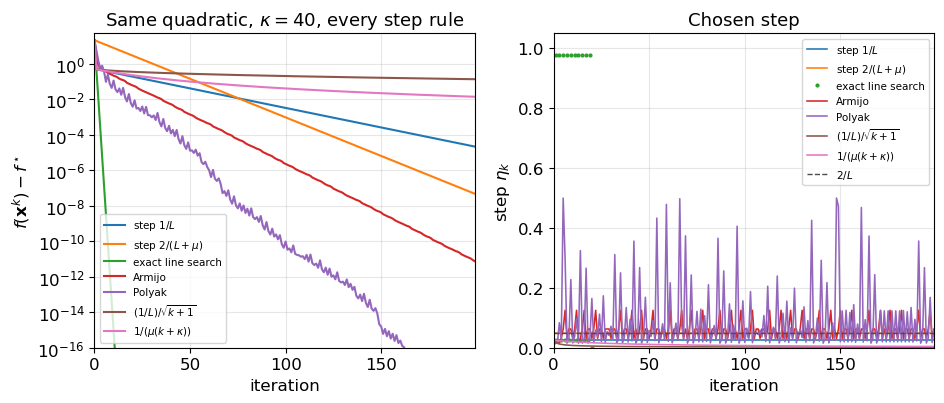

L         f_last=2.103e-05  median eta=0.025  max eta=0.025  f increased on   0 steps  distance monotone=True  f-evals=200
opt       f_last=4.650e-08  median eta=0.049  max eta=0.049  f increased on   0 steps  distance monotone=True  f-evals=200
exact     f_last=4.132e-32  median eta=0.025  max eta=0.976  f increased on   0 steps  distance monotone=True  f-evals=21
armijo    f_last=7.387e-12  median eta=0.062  max eta=0.125  f increased on   0 steps  distance monotone=True  f-evals=603
polyak    f_last=3.921e-20  median eta=0.036  max eta=0.500  f increased on  78 steps  distance monotone=True  f-evals=200
sqrt      f_last=1.305e-01  median eta=0.002  max eta=0.025  f increased on   0 steps  distance monotone=True  f-evals=200
decay     f_last=1.343e-02  median eta=0.007  max eta=0.025  f increased on   0 steps  distance monotone=True  f-evals=200


In [11]:
rules = [
    ("L", r"step $1/L$"),
    ("opt", r"step $2/(L+\mu)$"),
    ("exact", "exact line search"),
    ("armijo", "Armijo"),
    ("polyak", "Polyak"),
    ("sqrt", r"$(1/L)/\sqrt{k+1}$"),
    ("decay", r"$1/(\mu(k+\kappa))$"),
]
n_rules = 200
runs = {key: run_quadratic(eigs, x_balanced, n_rules, key) for key, _ in rules}

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
ax = axes[0]
for key, label in rules:
    ax.semilogy(positive(runs[key]["f"]), label=label)
ax.set_xlim(0, n_rules - 1)
ax.set_ylim(1e-16, 50)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(\mathbf{x}^k)-f^\star$")
ax.set_title(r"Same quadratic, $\kappa=40$, every step rule")
ax.legend(fontsize=7.5, loc="lower left")

ax = axes[1]
for key, label in rules:
    eta = runs[key]["eta"]
    if key == "exact":
        ax.plot(eta, ls="none", marker=".", ms=4, label=label)
    else:
        ax.plot(eta, lw=1.15, label=label)
ax.axhline(2.0 / L, color="0.3", ls="--", lw=1, label=r"$2/L$")
ax.set_xlim(0, n_rules - 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("iteration")
ax.set_ylabel(r"step $\eta_k$")
ax.set_title("Chosen step")
ax.legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
plt.show()

for key, label in rules:
    hist = runs[key]
    f = hist["f"]
    increased = int(np.sum(np.diff(f) > 1e-10 * np.maximum(f[:-1], 1e-30)))
    dist = np.linalg.norm(hist["x"], axis=1)
    dmono = bool(np.all(np.diff(dist) <= 1e-9))
    print(
        f"{key:8s}  f_last={f[-1]:.3e}  median eta={np.median(hist['eta']):.3f}"
        f"  max eta={hist['eta'].max():.3f}  f increased on {increased:3d} steps"
        f"  distance monotone={dmono}  f-evals={hist['n_f']}"
    )

## What survives when the step is no longer the one in the proof

- Same problem as the left panel above: $\kappa=40$, start $(1,1)$.

**Exact line search, the optimal fixed step, and Armijo.**

- Exact line search and the step $2/(L+\mu)$ are the two steep straight lines.
- Exact search is steeper on this start than its worst-case factor, and it reaches numerical zero in about twenty iterations.
- Armijo, told neither $L$ nor $\mu$, stays with the optimal fixed step and then pulls ahead of it.
- Its trial length starts at $1$, forty times $1/L$, and the first iteration spends several function evaluations shrinking the trial by halves.
- The evaluation counter under the figure is the cost the horizontal axis hides: about three value queries per iteration.
- On a quadratic the exact step spends one Rayleigh quotient, and on this start it does so about twenty times.

**Polyak.**

- This step uses $f^\star$, which the others were not given.
- The function value increases on 78 of the 200 steps.
- The longest step is $0.5$, twenty times $1/L$ and ten times $2/L$.
- The distance to the origin decreases at every iteration, as the inner-product argument promised.
- On a semilog plot of the gap, those increases are the wiggles.
- Convergence here is in the distance. The sequence of values is not monotone.

**Diminishing steps.**

- Both schedules lose the straight line.
- $(1/L)/\sqrt{k+1}$ shares the first step with the constant rule and then starves the iteration.
- $1/(\mu(k+\kappa))$ knows the strong-convexity modulus and still decays: it knows $\mu$, and it gives up the linear rate $\mu$ would have bought.
- On this deterministic quadratic, the constant step is the better use of the same information.

**The step plot.**

- Constant rules are horizontal lines.
- Exact search and Armijo move with the direction.
- The Polyak step spikes above the dashed line at $2/L$.
- The diminishing steps slide toward zero. That slide is the linear rate leaving the picture.


iterations to gap < 1e-06, flat start, initial gap 1/2
   kappa       1/L    2/(L+mu)
      10        63          33
      40       260         132
     160      1047         525


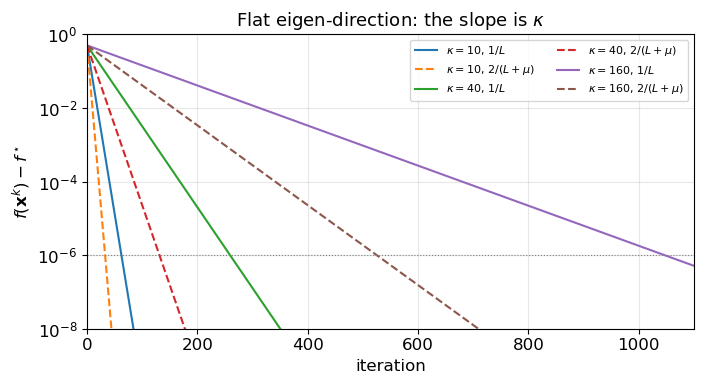

In [20]:
# Flat start, three condition numbers. Initial gap is 1/2 for every kappa.
kappas = (10.0, 40.0, 160.0)
target = 1e-6
n_kappa = 1400

fig, ax = plt.subplots()
print(f"iterations to gap < {target:.0e}, flat start, initial gap 1/2")
print(f"{'kappa':>8s}  {'1/L':>8s}  {'2/(L+mu)':>10s}")
for kappa_i in kappas:
    eigs_i = np.array([1.0, kappa_i])
    counts = {}
    for rule, style in (("L", "-"), ("opt", "--")):
        hist = run_quadratic(eigs_i, np.array([1.0, 0.0]), n_kappa, rule)
        hit = np.where(hist["f"] < target)[0]
        counts[rule] = int(hit[0]) if len(hit) else None
        label = rf"$\kappa={kappa_i:.0f}$, " + (r"$1/L$" if rule == "L" else r"$2/(L+\mu)$")
        ax.semilogy(positive(hist["f"]), ls=style, label=label)
    print(f"{kappa_i:8.0f}  {counts['L']:8d}  {counts['opt']:10d}")

ax.axhline(target, color="0.5", lw=0.8, ls=":")
ax.set_xlim(0, 1100)
ax.set_ylim(1e-8, 1)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(\mathbf{x}^k)-f^\star$")
ax.set_title(r"Flat eigen-direction: the slope is $\kappa$")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

## Conditioning moves the slope

- The start is the flat unit eigenvector for every curve, so the initial gap is $1/2$ independently of $\kappa$.
- The step $1/L$ has gap $\tfrac12(1-1/\kappa)^{2k}$.
- The step $2/(L+\mu)$ has gap $\tfrac12\bigl((\kappa-1)/(\kappa+1)\bigr)^{2k}$.
- Reaching $10^{-6}$ takes about $63$, $260$, and $1050$ iterations at $\kappa=10$, $40$, $160$ for the step $1/L$, and about half of that for $2/(L+\mu)$.
- The printed counts are those numbers.
- Multiplying $\kappa$ by $16$ multiplies the budget by about $16$.
- The dimension, the start, the target, and the choice of step stay fixed. The factor $\kappa$ in $k\ge \kappa\log(\Delta/\varepsilon)$ is the whole picture.
- At $\kappa=160$, a few hundred iterations of a correctly tuned gradient method have barely moved the gap.
- That is the method working as proved.


# 6. Logistic regression

- Labels $y_i\in\{-1,+1\}$, rows $\mathbf{a}_i\in\mathbb{R}^n$, optional ridge $\lambda\ge 0$:

$$
f(\mathbf{w})
= \frac{1}{m}\sum_{i=1}^m \log\bigl(1+\exp(-y_i\mathbf{a}_i^\top\mathbf{w})\bigr) + \frac{\lambda}{2}\|\mathbf{w}\|^2.
$$

- The gradient of one summand is $-y_i\mathbf{a}_i\big/\bigl(1+\exp(y_i\mathbf{a}_i^\top\mathbf{w})\bigr)$.
- Differentiating again, the Hessian of the average loss is

$$
\frac{1}{m}A^\top \mathrm{Diag}\bigl(\sigma_i(1-\sigma_i)\bigr) A + \lambda I,
$$

- The weights satisfy $\sigma_i(1-\sigma_i)\le 1/4$.

- Therefore $f$ is $L$-smooth with

$$
L = \frac{\|A\|_2^2}{4m} + \lambda,
$$

- $\|A\|_2$ is the largest singular value of the data matrix.

- This $L$ is computable before any iteration.
- It is also pessimistic: equality would require $\sigma_i(1-\sigma_i)=1/4$ on every row that carries the top singular direction, and $\sigma(1-\sigma)=1/4$ only at a zero margin.
- With $\lambda=0$ the global strong-convexity modulus is $0$.
- Far from the origin the weights $\sigma_i(1-\sigma_i)$ tend to $0$, so the smallest eigenvalue of the Hessian tends to $0$.
- The linear-rate theorem does not apply on $\mathbb{R}^n$.
- The convex $1/k$ theorem applies whenever a minimizer exists.
- Locally, near a minimizer whose Hessian is positive definite, the iteration settles into a linear regime. The rate is the condition number of that Hessian.
- The plot shows a linear tail. That tail lies outside the global hypothesis.
- Newton's method computes the reference value $f^\star$ used in the gaps and in the Polyak step.
- A few Newton steps suffice on this convex loss.
- Newton supplies that number. The curves drawn afterwards are first-order methods.


L = 3.0096   f* = 0.3730   ||grad at Newton|| = 9.08e-17
Hessian at w*: eigenvalues [8.750e-04, 1.055e+00], local kappa = 1206.0
global strong-convexity modulus = 0    R = ||w*|| = 2.133
L / lambda_max(H(w*)) = 2.85


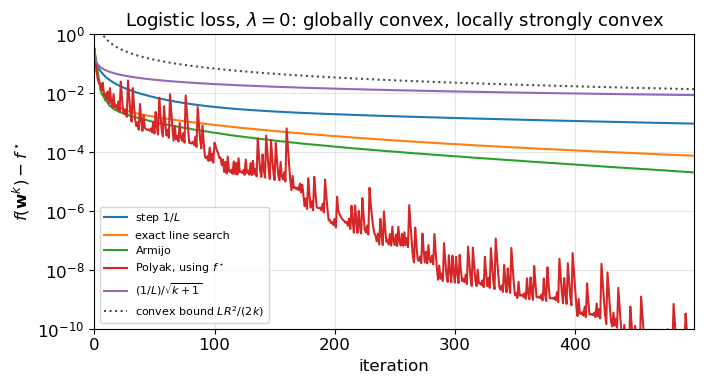

step 1/L: gap at k=50, 200, 500: 7.252e-03, 1.931e-03, 9.265e-04
median late contraction of the gap, iterations 400-499: 0.997945
local quadratic factor (1-1/kappa_loc)^2 = 0.998342
convex bound at k=400: 0.0171
  L        gap[500]=9.265e-04  median eta=0.332  f-evals=500
  exact    gap[500]=7.499e-05  median eta=1.699  f-evals=500
  armijo   gap[500]=2.043e-05  median eta=2.000  f-evals=1497
  polyak   gap[500]=4.172e-11  median eta=1.373  f-evals=500
  sqrt     gap[500]=8.631e-03  median eta=0.021  f-evals=500


In [21]:
def make_logistic(m, n, cond, noise, signal, lam, rng):
    """Columns scaled over a range `cond`, labels flipped with probability `noise`."""
    scales = np.geomspace(1.0, 1.0 / cond, n)
    A = rng.normal(size=(m, n)) * scales
    w_true = np.ones(n) / np.sqrt(n)
    A *= signal / np.std(A @ w_true)
    y = np.sign(A @ w_true)
    y[y == 0.0] = 1.0
    y = np.where(rng.random(m) < noise, -y, y)
    smax = float(np.linalg.svd(A, compute_uv=False)[0])
    L = smax ** 2 / (4.0 * m) + lam
    return A, y, L, w_true


def logistic_value(w, A, y, lam):
    z = y * (A @ w)
    return float(np.mean(np.logaddexp(0.0, -z)) + 0.5 * lam * np.dot(w, w))


def logistic_grad_hess(w, A, y, lam):
    z = y * (A @ w)
    s = 1.0 / (1.0 + np.exp(np.clip(z, -40.0, 40.0)))
    m = A.shape[0]
    g = -(A.T @ (y * s)) / m + lam * w
    d = s * (1.0 - s)
    H = ((A.T * d) @ A) / m + lam * np.eye(A.shape[1])
    return g, H


def logistic_newton(A, y, lam, n_iter=25):
    w = np.zeros(A.shape[1])
    for _ in range(n_iter):
        g, H = logistic_grad_hess(w, A, y, lam)
        step = np.linalg.solve(H, g)
        w = w - step
        if np.linalg.norm(step) < 1e-14:
            break
    return w


def run_logistic(A, y, lam, L, f_star, n_iter, rule):
    w = np.zeros(A.shape[1])
    alpha, beta = 0.5, 0.5
    f_hist, eta_hist = [], []
    eta_prev = 1.0
    n_f = 0
    for k in range(n_iter):
        value = logistic_value(w, A, y, lam)
        g, H = logistic_grad_hess(w, A, y, lam)
        n_f += 1
        f_hist.append(value - f_star)
        gn2 = float(np.dot(g, g))
        if gn2 < 1e-30:
            eta_hist.append(0.0)
            break
        if rule == "L":
            eta = 1.0 / L
        elif rule == "armijo":
            eta = 1.0 if k == 0 else eta_prev / beta
            for _ in range(60):
                if logistic_value(w - eta * g, A, y, lam) <= value - alpha * eta * gn2:
                    n_f += 1
                    break
                n_f += 1
                eta *= beta
            eta_prev = eta
        elif rule == "exact":
            eta = 0.0
            for _ in range(12):
                g_line, H_line = logistic_grad_hess(w - eta * g, A, y, lam)
                slope = -float(np.dot(g, g_line))
                curv = float(np.dot(g, H_line @ g))
                if curv <= 1e-18:
                    break
                eta_next = eta - slope / curv
                if eta_next < 0.0:
                    eta_next = 0.0
                if abs(eta_next - eta) < 1e-14:
                    eta = eta_next
                    break
                eta = eta_next
        elif rule == "polyak":
            eta = max(value - f_star, 0.0) / gn2
        elif rule == "sqrt":
            eta = (1.0 / L) / np.sqrt(k + 1.0)
        else:
            raise ValueError(rule)
        eta_hist.append(float(eta))
        w = w - eta * g
    return {"f": np.asarray(f_hist), "eta": np.asarray(eta_hist), "n_f": n_f, "w": w}


m_log, n_log = 300, 12
cond_log, noise_log, signal_log, lam_log = 40.0, 0.08, 1.4, 0.0
A, y, L_log, w_true = make_logistic(m_log, n_log, cond_log, noise_log, signal_log, lam_log, np.random.default_rng(0))
w_star = logistic_newton(A, y, lam_log)
f_star = logistic_value(w_star, A, y, lam_log)
g_star, H_star = logistic_grad_hess(w_star, A, y, lam_log)
eig_H = np.linalg.eigvalsh(H_star)
kappa_loc = float(eig_H[-1] / eig_H[0])
R_log = float(np.linalg.norm(w_star))
print(f"L = {L_log:.4f}   f* = {f_star:.4f}   ||grad at Newton|| = {np.linalg.norm(g_star):.2e}")
print(f"Hessian at w*: eigenvalues [{eig_H[0]:.3e}, {eig_H[-1]:.3e}], local kappa = {kappa_loc:.1f}")
print(f"global strong-convexity modulus = {lam_log:.0f}    R = ||w*|| = {R_log:.3f}")
print(f"L / lambda_max(H(w*)) = {L_log / eig_H[-1]:.2f}")

log_rules = [
    ("L", r"step $1/L$"),
    ("exact", "exact line search"),
    ("armijo", "Armijo"),
    ("polyak", r"Polyak, using $f^\star$"),
    ("sqrt", r"$(1/L)/\sqrt{k+1}$"),
]
n_log = 500
log_runs = {key: run_logistic(A, y, lam_log, L_log, f_star, n_log, key) for key, _ in log_rules}

fig, ax = plt.subplots()
for key, label in log_rules:
    ax.semilogy(positive(log_runs[key]["f"]), label=label)
k_pos = np.arange(1, n_log)
ax.semilogy(k_pos, L_log * R_log**2 / (2.0 * k_pos), ls=":", color="0.3", label=r"convex bound $LR^2/(2k)$")
ax.set_xlim(0, n_log - 1)
ax.set_ylim(1e-10, 1)
ax.set_xlabel("iteration")
ax.set_ylabel(r"$f(\mathbf{w}^k)-f^\star$")
ax.set_title(r"Logistic loss, $\lambda=0$: globally convex, locally strongly convex")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

f_const = log_runs["L"]["f"]
late = f_const[401:] / f_const[400:-1]
print(f"step 1/L: gap at k=50, 200, 500: {f_const[50]:.3e}, {f_const[200]:.3e}, {f_const[-1]:.3e}")
print(f"median late contraction of the gap, iterations 400-499: {np.median(late):.6f}")
print(f"local quadratic factor (1-1/kappa_loc)^2 = {(1 - 1/kappa_loc)**2:.6f}")
print(f"convex bound at k=400: {L_log * R_log**2 / (2 * 400):.4f}")
for key, _ in log_rules:
    hist = log_runs[key]
    print(f"  {key:8s} gap[500]={hist['f'][-1]:.3e}  median eta={np.median(hist['eta']):.3f}  f-evals={hist['n_f']}")

## Global $1/k$, and a linear tail the hypothesis cannot see

- The instance has $m=300$ rows and $n=12$ columns, with column scales spread by a factor $40$.
- Eight percent of the labels are flipped, so the two classes overlap and a finite minimizer exists.
- There is no ridge.
- $L\approx 3$ is the closed-form smoothness constant.
- The largest eigenvalue of the Hessian at the minimizer is about three times smaller: the factor $1/4$ in $\|A\|_2^2/(4m)$ is not attained on this data.
- The smallest eigenvalue is about $10^{-3}$, so the local condition number is about $1.2\cdot 10^3$.
- The global modulus is zero. Both statements are true of the same function, on different domains.
- The convex bound $LR^2/(2k)$ is the dashed curve. At iteration $400$ it reads $0.017$, while the constant-step gap is about $10^{-3}$.
- The bound is valid and loose, for the same reason as on the quadratic: it has to cover every convex function with this $L$ and this $R$, and this loss is better than that worst function.
- The constant step $1/L$ drops for a few dozen iterations and then becomes a straight line.
- Over iterations 400 to 500 the contraction of the gap is $0.998$ per step, next to $(1-1/\kappa_{\mathrm{loc}})^2 = 0.9983$, the factor a quadratic with this Hessian would have under the step $1/L$.
- That linear tail is real, and it lies outside the global theorem: the strong-convexity modulus on $\mathbb{R}^n$ is zero, so the theorem on the books is the dashed $1/k$ curve.
- Armijo's accepted steps have median $2$, against $1/L\approx 0.33$.
- The test sees the true decrease along the gradient. The true directional curvature is well below the global $L$, so a step the worst-case lemma would have rejected passes the inequality Armijo actually checks.
- Exact line search does the same, with a one-dimensional Newton step on the line.
- The Polyak step, given $f^\star$ from Newton, is the fastest curve here, and it is not monotone. Its proved guarantee is only the same order as $1/L$.
- The diminishing schedule is last. It was given $L$, and it gave the linear tail away.
- A constant several times larger than $1/L$ can still converge here, because $2/L$ was computed from an upper bound on the curvature rather than from the curvature along the path.
- The safe a-priori step remains $1/L$.
- Armijo is how the iteration discovers that the path is easier than the a-priori bound.


## Separable labels: the gap goes to zero and the iterates do not

- Drop the label noise and keep $\lambda=0$.
- If a direction $\mathbf{w}$ has $y_i\mathbf{a}_i^\top\mathbf{w}>0$ for every $i$, then $f(t\mathbf{w})\to 0$ as $t\to\infty$, while $f(\mathbf{w})>0$ for every finite $\mathbf{w}$.
- The infimum is $0$, and it is not attained.
- There is no $\mathbf{x}^\star$ and no finite $R$, so the convex last-iterate bound $LR^2/(2k)$ has nothing to stand on.
- The stationarity theorem still applies. The loss is nonnegative and $L$-smooth, with the same formula for $L$, so

$$
\min_{k<K}\|f'(\mathbf{w}^k)\|
\le \sqrt{\frac{2L\, f(\mathbf{w}^0)}{K}}.
$$

- Gradient descent with step $1/L$ drives the gradient toward zero, drives the loss toward zero, and drives $\|\mathbf{w}\|$ upward.
- A vanishing gradient is a different statement from a converging iterate.
- The direction the iterates eventually travel is the max-margin separator. The figure shows the norm, and the citation in the references records the theorem.


minimum margin of the planted direction: 0.0004
L = 0.0296.  A positive margin means the data are separable and no minimizer exists.


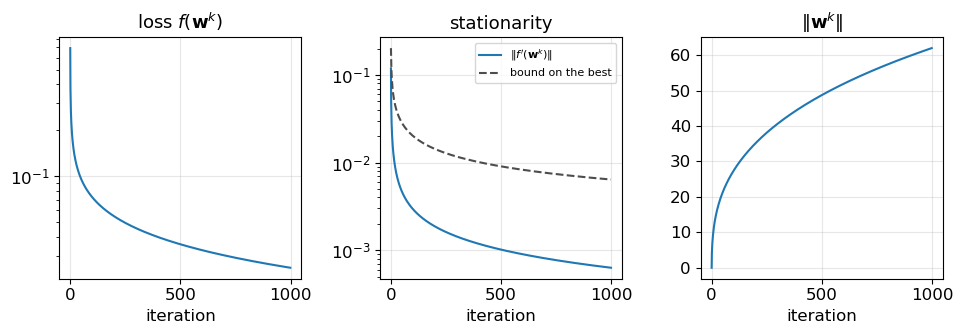

k=1000:  f=2.4972e-02   ||grad||=6.3017e-04   ||w||=62.0
bound on the best gradient at k=1000: 6.4016e-03
best gradient actually seen: 6.3017e-04


In [8]:
rng_sep = np.random.default_rng(2)
m_sep, n_sep = 180, 12
A_sep = rng_sep.normal(size=(m_sep, n_sep))
A_sep /= np.linalg.norm(A_sep, axis=1, keepdims=True)
w_sep = rng_sep.normal(size=n_sep)
w_sep /= np.linalg.norm(w_sep)
y_sep = np.sign(A_sep @ w_sep)
y_sep[y_sep == 0.0] = 1.0
margins = y_sep * (A_sep @ w_sep)
smax_sep = np.linalg.svd(A_sep, compute_uv=False)[0]
L_sep = float(smax_sep**2 / (4.0 * m_sep))
print(f"minimum margin of the planted direction: {margins.min():.4f}")
print(f"L = {L_sep:.4f}.  A positive margin means the data are separable and no minimizer exists.")

n_sep_iter = 1000
w = np.zeros(n_sep)
f_sep, g_sep, nrm_sep = [], [], []
for k in range(n_sep_iter):
    z = y_sep * (A_sep @ w)
    f_sep.append(float(np.mean(np.logaddexp(0.0, -z))))
    s = 1.0 / (1.0 + np.exp(np.clip(z, -40.0, 40.0)))
    g = -(A_sep.T @ (y_sep * s)) / m_sep
    g_sep.append(float(np.linalg.norm(g)))
    nrm_sep.append(float(np.linalg.norm(w)))
    w = w - (1.0 / L_sep) * g
f_sep = np.asarray(f_sep)
g_sep = np.asarray(g_sep)
nrm_sep = np.asarray(nrm_sep)
best_g = np.minimum.accumulate(g_sep)
k_pos = np.arange(1, n_sep_iter + 1)
stationarity_bound = np.sqrt(2.0 * L_sep * f_sep[0] / k_pos)

fig, axes = plt.subplots(1, 3, figsize=(9.8, 3.5))
axes[0].semilogy(f_sep, color="C0")
axes[0].set_title(r"loss $f(\mathbf{w}^k)$")
axes[0].set_xlabel("iteration")
axes[1].semilogy(g_sep, color="C0", label=r"$\|f'(\mathbf{w}^k)\|$")
axes[1].semilogy(stationarity_bound, color="0.3", ls="--", label=r"bound on the best")
axes[1].set_title("stationarity")
axes[1].set_xlabel("iteration")
axes[1].legend(fontsize=8)
axes[2].plot(nrm_sep, color="C0")
axes[2].set_title(r"$\|\mathbf{w}^k\|$")
axes[2].set_xlabel("iteration")
fig.tight_layout()
plt.show()

print(f"k=1000:  f={f_sep[-1]:.4e}   ||grad||={g_sep[-1]:.4e}   ||w||={nrm_sep[-1]:.1f}")
print(f"bound on the best gradient at k=1000: {stationarity_bound[-1]:.4e}")
print(f"best gradient actually seen: {best_g[-1]:.4e}")

## What this run is allowed to claim

- The loss falls from $\log 2$ toward zero, and the gradient falls with it.
- On this run the gradient itself decreases, so the last gradient and the best gradient along the path coincide.
- Both stay under the stationarity bound drawn in the middle panel. That is the theorem that applies.
- The norm of the weights grows from $0$ past $60$ in a thousand iterations, and it has not levelled off.
- There is no distance $\|\mathbf{w}^k-\mathbf{w}^\star\|$ to plot, because there is no finite minimizer.
- A small gradient, read as if the weights had converged, would contradict the right-hand panel.
- Adding a ridge $\lambda>0$ restores a finite minimizer and a global modulus $\mu=\lambda$.
- The price is a different problem: the minimizer moves, and the condition number is at least $L/\lambda$.
- Whether that trade is acceptable is a modeling question. The bounds say what each choice costs.


# 7. Several minima

- The stationarity theorem produces a point with a small gradient.
- Which critical point that is depends on the start.
- The theorem has no variable in which to name the critical point.

- The one-dimensional example is a double well with no global Lipschitz constant:

$$
f(t) = \frac14 t^4 - \frac12 t^2 + 0.15\, t,
\qquad
f'(t) = t^3 - t + 0.15,
\qquad
f''(t) = 3t^2 - 1.
$$

- $f''(t)\to\infty$ as $|t|\to\infty$, so no single $L$ is legal on $\mathbb{R}$ and the step $1/L$ is undefined.
- On any bounded interval $f''$ is bounded, so the function is smooth there.
- Armijo only ever needs the curvature of the segment it tests.
- There are three real roots of $f'$.
- The left root is a local minimizer, value about $-0.405$.
- The middle root is a local maximizer.
- The right root is a local minimizer, value about $-0.106$.
- A gradient that is numerically zero is available at both minimizers.
- The two values differ by about $0.3$.


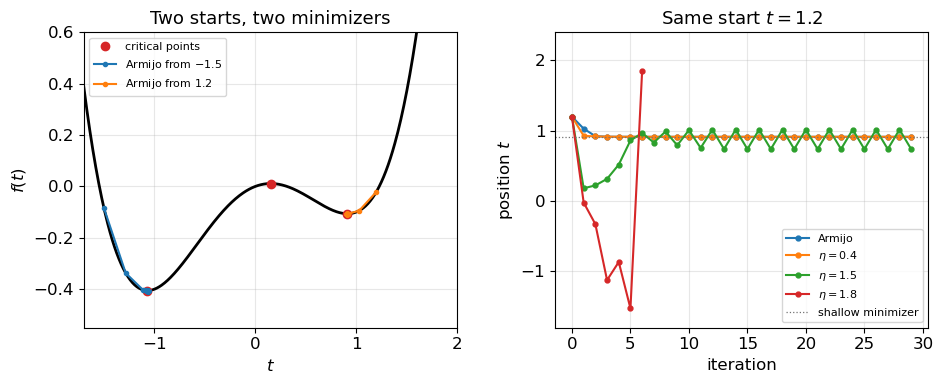

critical points (sign changes of f'):
  t=-1.0684   f=-0.4053   f''=2.424
  t=0.1536   f=0.0114   f''=-0.929
  t=0.9141   f=-0.1061   f''=1.507
Armijo limits:
  from -1.50 -> -1.0679   f=-0.4053   |f'|=2.82e-11
  from -0.20 -> -1.0679   f=-0.4053   |f'|=7.40e-12
  from  0.30 ->  0.9143   f=-0.1061   |f'|=3.58e-15
  from  1.20 ->  0.9143   f=-0.1061   |f'|=1.62e-09
constant steps from t=1.2:
  eta=0.4  steps kept=40/40  last t=0.9143  |f'| at previous=8.327e-17
  eta=1.5  steps kept=40/40  last t=0.7394  |f'| at previous=1.852e-01
  eta=1.8  steps kept=7/9  last t=496.2  |f'| at previous=2.794e+02


In [22]:
def f_well(t):
    return 0.25 * t**4 - 0.5 * t**2 + 0.15 * t


def df_well(t):
    return t**3 - t + 0.15


def armijo_well(t, n_iter=40):
    path_t, path_f = [], []
    for _ in range(n_iter):
        g = df_well(t)
        path_t.append(t)
        path_f.append(f_well(t))
        if abs(g) < 1e-14:
            break
        eta, value, g2 = 1.0, f_well(t), g * g
        for _ in range(40):
            if f_well(t - eta * g) <= value - 0.5 * eta * g2:
                break
            eta *= 0.5
        t = t - eta * g
    return np.asarray(path_t), np.asarray(path_f)


def constant_well(t, eta, n_iter=40, limit=30.0):
    path_t, path_f = [], []
    for _ in range(n_iter):
        g = df_well(t)
        path_t.append(t)
        path_f.append(f_well(t))
        t = t - eta * g
        if abs(t) > limit:
            path_t.append(t)
            path_f.append(f_well(t))
            break
    return np.asarray(path_t), np.asarray(path_f)


grid = np.linspace(-1.6, 1.5, 6001)
sign_change = np.where(np.diff(np.sign(df_well(grid))))[0]
roots = grid[sign_change]

t_plot = np.linspace(-1.7, 2.0, 500)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0))
ax = axes[0]
ax.plot(t_plot, f_well(t_plot), color="k", lw=2)
ax.plot(roots, f_well(roots), "o", color="C3", ms=6, label="critical points")
for t0, color in ((-1.5, "C0"), (1.2, "C1")):
    path_t, path_f = armijo_well(t0)
    ax.plot(path_t, path_f, marker="o", ms=3, color=color, label=rf"Armijo from ${t0}$")
ax.set_xlim(-1.7, 2.0)
ax.set_ylim(-0.55, 0.6)
ax.set_xlabel("$t$")
ax.set_ylabel("$f(t)$")
ax.set_title("Two starts, two minimizers")
ax.legend(fontsize=8)

ax = axes[1]
series = [
    ("Armijo", armijo_well(1.2, n_iter=30)),
    (r"$\eta=0.4$", constant_well(1.2, 0.4, n_iter=30)),
    (r"$\eta=1.5$", constant_well(1.2, 1.5, n_iter=30)),
    (r"$\eta=1.8$", constant_well(1.2, 1.8, n_iter=12)),
]
for label, (path_t, path_f) in series:
    visible = np.abs(path_t) < 4
    ax.plot(np.flatnonzero(visible), path_t[visible], marker="o", ms=3.5, label=label)
ax.axhline(roots[2], color="0.45", lw=0.9, ls=":", label="shallow minimizer")
ax.set_ylim(-1.8, 2.4)
ax.set_xlabel("iteration")
ax.set_ylabel(r"position $t$")
ax.set_title(r"Same start $t=1.2$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("critical points (sign changes of f'):")
for r in roots:
    print(f"  t={r:.4f}   f={f_well(r):.4f}   f''={3 * r * r - 1:.3f}")
print("Armijo limits:")
for t0 in (-1.5, -0.2, 0.3, 1.2):
    path_t, path_f = armijo_well(t0)
    print(
        f"  from {t0:5.2f} -> {path_t[-1]:7.4f}   f={path_f[-1]:.4f}"
        f"   |f'|={abs(df_well(path_t[-1])):.2e}"
    )
print("constant steps from t=1.2:")
for eta in (0.4, 1.5, 1.8):
    path_t, path_f = constant_well(1.2, eta, n_iter=40)
    inside = np.abs(path_t) < 5
    print(
        f"  eta={eta:.1f}  steps kept={int(inside.sum())}/{len(path_t)}"
        f"  last t={path_t[-1]:.4g}  |f'| at previous={abs(df_well(path_t[-2])):.3e}"
    )

## Initialization picks the well. The step picks convergence.

- Armijo from $-1.5$ and from $-0.2$ finishes at the deep minimizer.
- Armijo from $0.3$ and from $1.2$ finishes at the shallow one.
- The basin boundary is the local maximizer near $t=0.15$.
- Every one of these runs ends with a gradient below $10^{-8}$.
- The stationarity certificate is the same in every run. The values differ by about $0.3$.

- From the same start $t=1.2$, to the right of the shallow well:
  - Armijo decreases $f$ at every accepted step and stops at the shallow minimizer.
  - The constant $\eta=0.4$ does the same. Locally the well has $f''\approx 1.5$, so $2/f''\approx 1.3$, and $0.4$ lies inside that neighborhood bound. The comparison uses the curvature at the minimizer. A single $L$ for the whole line is still unavailable.
  - The constant $\eta=1.5$ settles onto a $2$-cycle, jumping between two points that straddle the shallow minimizer. The gradient on that cycle stays near $0.2$. The iteration is bounded and stays away from every stationary point. The hypothesis $\eta<2/L$ of the descent lemma is unavailable here, and the conclusion fails in the picture.
  - The constant $\eta=1.8$ leaves every bounded window within a few iterations. Lengthening the step past this well sends the iterate out of the window.

- The Polyak formula, fed the **global** value $f^\star\approx -0.405$, refuses the shallow well.
- There $f-f^\star\approx 0.3$ while the gradient is tiny, so the step $(f-f^\star)/|f'|^2$ is enormous and the iterate is thrown out of the basin.
- The distance argument used convexity. This $f$ is nonconvex, so the formula can leave the basin.


## A saddle, and two wells of different depth

- In two variables, with a tilt that makes the left wells deeper,

$$
f(x,y) = (x^2-1)^2 + (y^2-1)^2 + 0.5\, x.
$$

- The partial derivative in $y$ is $4y(y^2-1)$.
- The line $y=0$ is invariant: a start on it stays on it.
- Restricted to that line, the iteration is the one-dimensional tilted well, and it converges to a point where $f_x=0$ and $f_y=0$.
- The second derivative $f_{yy}=12y^2-4$ equals $-4$ there, while $f_{xx}$ is positive, so the point is a saddle.
- A start with both coordinates nonzero leaves the line.
- Armijo from a grid of starts finds four local minimizers.
- The two on the left, with $x<0$, have the smaller value.
- The two on the right have a value about one unit higher.
- Starts placed exactly on $y=0$ finish at a saddle, with a gradient numerically zero and a value close to the shallow wells.
- A start a little off the line falls into a well.
- Stationarity does not separate these outcomes. The basin picture does.


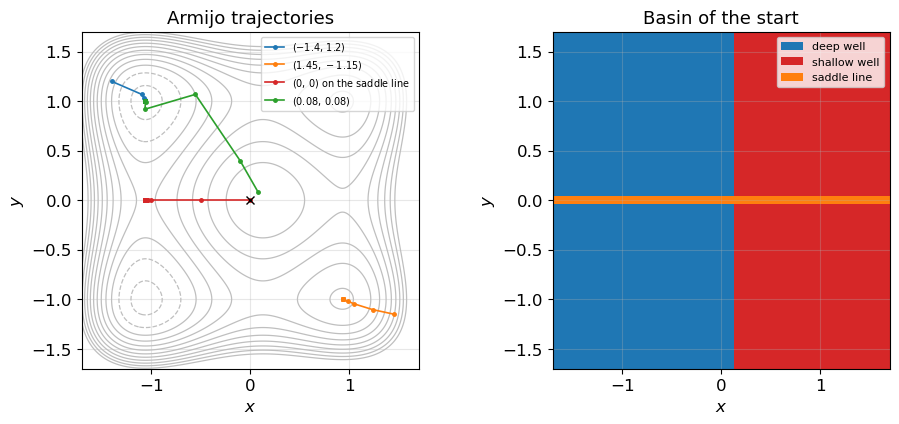

Left panel. One block per drawn trajectory. The limit is the last Armijo point.
f = (x^2 - 1)^2 + (y^2 - 1)^2 + 0.5 x, printed as those three terms in that order.
||grad|| is the stationarity residual at the limit. A tiny value means the run has stopped at a critical point.
  upper left: start (-1.40,  1.20) -> ( -1.057,   1.000)  deep well
    f =  -0.5148 =   0.01397 +   0.00000 +  -0.52873
    ||grad|| = 2.77e-10 after 35 accepted steps
  lower right: start ( 1.45, -1.15) -> (  0.930,  -1.000)  shallow well
    f =   0.4833 =   0.01805 +   0.00000 +   0.46520
    ||grad|| = 4.70e-10 after 21 accepted steps
  on y = 0: start ( 0.00,  0.00) -> ( -1.057,   0.000)  saddle
    f =   0.4852 =   0.01397 +   1.00000 +  -0.52873
    ||grad|| = 1.83e-08 after 60 accepted steps
  just off y = 0: start ( 0.08,  0.08) -> ( -1.057,   1.000)  deep well
    f =  -0.5148 =   0.01397 +   0.00000 +  -0.52873
    ||grad|| = 1.55e-08 after 60 accepted steps
Right panel: 41 x 41 = 1681 starts on [-1.7, 1

In [ ]:
import matplotlib.patches as mpatches


def f_landscape(xy):
    x, y = xy[..., 0], xy[..., 1]
    return (x * x - 1.0) ** 2 + (y * y - 1.0) ** 2 + 0.5 * x


def armijo_landscape(x, y, n_iter=60):
    path = [(x, y)]
    for _ in range(n_iter):
        gx = 4.0 * x * (x * x - 1.0) + 0.5
        gy = 4.0 * y * (y * y - 1.0)
        gn2 = gx * gx + gy * gy
        if gn2 < 1e-18:
            break
        eta = 1.0
        value = (x * x - 1.0) ** 2 + (y * y - 1.0) ** 2 + 0.5 * x
        for _ in range(40):
            xn = x - eta * gx
            yn = y - eta * gy
            fn = (xn * xn - 1.0) ** 2 + (yn * yn - 1.0) ** 2 + 0.5 * xn
            if fn <= value - 0.5 * eta * gn2:
                break
            eta *= 0.5
        x, y = x - eta * gx, y - eta * gy
        path.append((x, y))
    return np.asarray(path)


def classify(x, y):
    if abs(y) < 0.25:
        return 0  # saddle, stuck on y = 0
    if x < 0.0:
        return 1  # deep well
    return 2  # shallow well


xs = np.linspace(-1.7, 1.7, 41)
ys = np.linspace(-1.7, 1.7, 41)
ys[len(ys) // 2] = 0.0
basin = np.empty((len(ys), len(xs)))
for i, y0 in enumerate(ys):
    for j, x0 in enumerate(xs):
        final = armijo_landscape(x0, y0, n_iter=50)[-1]
        basin[i, j] = classify(final[0], final[1])

# A few trajectories, and the constant step that leaves the window.
tracked = [(-1.4, 1.2), (1.45, -1.15), (0.0, 0.0), (0.08, 0.08)]
tracked_paths = [armijo_landscape(*p) for p in tracked]

xx, yy = np.meshgrid(np.linspace(-1.7, 1.7, 250), np.linspace(-1.7, 1.7, 250))
zz = f_landscape(np.stack([xx, yy], axis=-1))

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4))
ax = axes[0]
# Negative level sets are dashed
ax.contour(xx, yy, zz, levels=np.linspace(-0.4, 3.0, 12), colors="0.75", linewidths=0.9)
colors = ["C0", "C1", "C3", "C2"]
labels = [r"$(-1.4,\,1.2)$", r"$(1.45,\,-1.15)$", r"$(0,\,0)$ on the saddle line", r"$(0.08,\,0.08)$"]
for path, color, label in zip(tracked_paths, colors, labels):
    ax.plot(path[:, 0], path[:, 1], marker="o", ms=2.5, lw=1.2, color=color, label=label)
ax.plot(0, 0, "x", color="k", ms=6)
ax.set_aspect("equal")
ax.set_xlim(-1.7, 1.7)
ax.set_ylim(-1.7, 1.7)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Armijo trajectories")
ax.legend(fontsize=7, loc="upper right")

ax = axes[1]
cmap = plt.matplotlib.colors.ListedColormap(["C1", "C0", "C3"])
ax.imshow(
    basin,
    origin="lower",
    extent=[-1.7, 1.7, -1.7, 1.7],
    cmap=cmap,
    vmin=-0.5,
    vmax=2.5,
    interpolation="nearest",
    aspect="equal",
)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Basin of the start")
ax.legend(
    handles=[
        mpatches.Patch(facecolor="C0", label="deep well"),
        mpatches.Patch(facecolor="C3", label="shallow well"),
        mpatches.Patch(facecolor="C1", label="saddle line"),
    ],
    fontsize=8,
    loc="upper right",
)
fig.tight_layout()
plt.show()

print("Left panel. One block per drawn trajectory. The limit is the last Armijo point.")
print("f = (x^2 - 1)^2 + (y^2 - 1)^2 + 0.5 x, printed as those three terms in that order.")
print("||grad|| is the stationarity residual at the limit. A tiny value means the run has stopped at a critical point.")
labels = ["upper left", "lower right", "on y = 0", "just off y = 0"]
kind_name = {0: "saddle", 1: "deep well", 2: "shallow well"}
for (x0, y0), path, label in zip(tracked, tracked_paths, labels):
    x, y = float(path[-1, 0]), float(path[-1, 1])
    bowl_x = (x * x - 1.0) ** 2
    bowl_y = (y * y - 1.0) ** 2
    tilt = 0.5 * x
    gx = 4.0 * x * (x * x - 1.0) + 0.5
    gy = 4.0 * y * (y * y - 1.0)
    print(f"  {label}: start ({x0:5.2f}, {y0:5.2f}) -> ({x:7.3f}, {y:7.3f})  {kind_name[classify(x, y)]}")
    print(f"    f = {bowl_x + bowl_y + tilt:8.4f} = {bowl_x:9.5f} + {bowl_y:9.5f} + {tilt:9.5f}")
    print(f"    ||grad|| = {np.hypot(gx, gy):.2e} after {len(path) - 1} accepted steps")

counts = {0: 0, 1: 0, 2: 0}
for value in basin.ravel():
    counts[int(value)] += 1
print(f"Right panel: {len(xs)} x {len(ys)} = {basin.size} starts on [-1.7, 1.7]^2. The color is the limit Armijo reached.")
print(f"  {counts[1]:4d} blue    limit has x < 0, so it is a deep well")
print(f"  {counts[2]:4d} red     limit has x > 0, so it is a shallow well")
print(f"  {counts[0]:4d} orange  limit has |y| < 0.25. These are the {counts[0]} starts of the grid row y = 0.")
print(f"  {counts[1]} + {counts[2]} + {counts[0]} = {sum(counts.values())}.")
print("  The deep side holds more starts: the tilt moves the boundary between the basins off the line x = 0.")

# A constant step with no global L, from a point Armijo handles.
print("Same start (1.3, 0.8), two rules. This point is in the shallow basin, on the right of the picture.")
x, y = 1.3, 0.8
for k in range(8):
    gx = 4 * x * (x * x - 1) + 0.5
    gy = 4 * y * (y * y - 1)
    x, y = x - 0.5 * gx, y - 0.5 * gy
    if abs(x) + abs(y) > 50:
        print(f"  Constant step 0.5: by iteration {k + 1} the point is ({x:.2f}, {y:.2f}).")
        print("  It has left the window. No global Lipschitz constant was computed for this length.")
        break
armijo_same = armijo_landscape(1.3, 0.8)[-1]
gx = 4 * armijo_same[0] * (armijo_same[0] ** 2 - 1) + 0.5
gy = 4 * armijo_same[1] * (armijo_same[1] ** 2 - 1)
print(
    f"  Armijo: stops at ({armijo_same[0]:.3f}, {armijo_same[1]:.3f}),"
    f" a shallow well, f = {f_landscape(armijo_same):.4f}, ||grad|| = {np.hypot(gx, gy):.2e}."
)
print("  f matches the lower-right trajectory because f(x, y) = f(x, -y). The test kept the step inside the well.")


## Same gradient, three kinds of point

- The color on the right is a property of the **start**.
- Blue reaches a deep well. Red reaches a shallow well.
- The thin orange stripe is the invariant line $y=0$, and starts on it reach the saddle.
- The stripe has no width. A perturbation off it falls into a well, which is what the start $(0.08, 0.08)$ does in the left panel, next to the start $(0,0)$ that stays on the line.
- The printed limits have a gradient of size $10^{-8}$ or smaller at a deep minimizer, at a shallow minimizer, and at the saddle.
- A printed step count of $60$ is the iteration budget. A smaller count means the stopping test $\|f'\|^2<10^{-18}$ already fired.
- The values are about $-0.51$, about $0.48$, and about $0.49$. The print splits each value into $(x^2-1)^2$, $(y^2-1)^2$, and the tilt $0.5x$.
- A point with a gradient of that size meets the $L$-smooth theorem, and the theorem has not named which point it is.
- The constant step $0.5$ from $(1.3, 0.8)$ leaves the window in a few iterations.
- Armijo from the same point converges to the shallow well.
- The difference is the sufficient-decrease test.
- There is still no global $L$ that would have licensed the constant $0.5$ in advance, and Armijo does not need one.


## Takeaway

- Gradient descent minimizes a quadratic upper model.
  - The step $1/L$ is the curvature of that model.
  - The step $2/L$ is the point past which the model stops promising decrease, and past which a quadratic with largest eigenvalue $L$ diverges.
- The class changes the residual and the budget.
  - $L$-smoothness gives stationarity in $O(L\Delta/\varepsilon^2)$.
  - Convexity gives a global gap in $O(LR^2/\varepsilon)$.
  - Strong convexity gives $O(\kappa\log(\Delta/\varepsilon))$.
  - Knowing both $L$ and $\mu$ improves the constant to the factor $(\kappa-1)/(\kappa+1)$ on the distance.
  - Each extra assumption is visible in the budget.
- The bounds are uniform over a class.
  - On a quadratic the optimal fixed step meets its bound with equality.
  - The Polyak–Łojasiewicz factor $1-1/\kappa$ on the gap is the square root of the truth.
  - The convex $1/k$ bound is valid, and it is loose whenever $\mu>0$.
  - A large $\kappa$ is a property of the problem, and a reason to change the method.
  - Lecture 1 recorded that the optimal first-order rate replaces $\kappa$ by $\sqrt{\kappa}$.
- The step can be chosen without forming both constants.
  - Exact line search matches the optimal fixed step in the worst case, and it is often faster on a kinder start. The price is a one-dimensional minimization, and the zigzag stays.
  - Armijo recovers a legal step from function values, including on functions with no global $L$.
  - Diminishing steps give away the linear rate.
  - The Polyak step needs $f^\star$. On convex smooth functions it may exceed $2/L$ and still decrease the distance, while the function values need not be monotone.
- Stationarity is the whole nonconvex guarantee.
  - The double well and the tilted landscape both finish with a tiny gradient at a deep minimizer, at a shallow minimizer, and, on the invariant line, at a saddle.
  - The start chooses the basin.
  - A constant step chosen with no Lipschitz constant can diverge, or lock onto a cycle on which the gradient stays away from zero.


### References

- **Book (the three theorems).** Y. Nesterov, *Lectures on Convex Optimization*, Springer, 2018, §2.1. The descent lemma, the convex rate $LR^2/(2k)$, and the strongly convex rates are this chapter. The factor $(\kappa-1)/(\kappa+1)$ is the fixed-step analysis there.
- **Survey.** S. Bubeck, [*Convex Optimization: Algorithms and Complexity*](https://arxiv.org/abs/1405.4980), Foundations and Trends in Machine Learning, 2015, §3.2–3.4. Same bounds, with the iteration complexity written as a budget.
- **Book (line search).** S. Boyd and L. Vandenberghe, [*Convex Optimization*](https://web.stanford.edu/~boyd/cvxbook/), Cambridge, 2004, §9.3: exact line search, backtracking, and the quadratic upper model. J. Nocedal and S. Wright, *Numerical Optimization*, Springer, 2006, Chapter 3, for the Armijo rule as used in general nonlinear optimization.
- **Armijo.** L. Armijo, [*Minimization of functions having Lipschitz continuous first partial derivatives*](https://projecteuclid.org/euclid.pjm/1102995080), Pacific Journal of Mathematics, 1966.
- **Polyak step and Polyak–Łojasiewicz.** B. T. Polyak, *Introduction to Optimization*, Optimization Software, 1987. The gradient form of the inequality used for the linear rate goes back to B. T. Polyak, *Gradient methods for the minimisation of functionals*, USSR Computational Mathematics and Mathematical Physics, 1963.
- **Exact line search, sharp constant.** E. de Klerk, F. Glineur, A. B. Taylor, [*On the worst-case complexity of the gradient method with exact line search for smooth strongly convex functions*](https://arxiv.org/abs/1606.09365), Optimization Letters, 2017. The factor $\bigl((\kappa-1)/(\kappa+1)\bigr)^2$ is their worst-case result.
- **Stationarity, matching lower bound.** Y. Carmon, J. Duchi, O. Hinder, A. Sidford, [*Lower bounds for finding stationary points I*](https://arxiv.org/abs/1710.11606), Mathematical Programming, 2020. The $1/\varepsilon^2$ upper bound proved in this lecture has the right power of $\varepsilon$.
- **Acceleration.** Lecture 1. The optimal first-order rate replaces $\kappa$ by $\sqrt{\kappa}$ and $1/k$ by $1/k^2$. Y. Nesterov, [*A method of solving a convex programming problem with convergence rate $O(1/k^2)$*](https://www.mathnet.ru/eng/dan/v269/i3/p543), Doklady AN SSSR, 1983.
- **Separable logistic loss.** D. Soudry, E. Hoffer, M. S. Nacson, S. Gunasekar, N. Srebro, [*The implicit bias of gradient descent on separable data*](https://arxiv.org/abs/1710.10345), JMLR, 2018. The growing norm in the separable experiment is their regime: the direction converges to the max-margin separator, and the weights diverge.